# 03 - Pruning

Creazione e confronto di modelli con vari livelli di sparsità
- confrontando sia global sparsity che layer sparsity
- la config salvata sia per student che teacher è quella che mantiene max 3% accuracy persa

In [1]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import torch, torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from src.data import get_dataloaders
from src.models import build_model
from src.quant import fold_bn
from src.prune import *
from src.metrics import profile_model, save_result, count_macs
from src.train import evaluate

In [3]:
device = torch.device("cpu")
_, val_loader, test_loader = get_dataloaders("../data", batch_size=128)

# 0.0 è no pruning, 0.98 è quasi tutti i pesi azzerati
SPARSITIES = [0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
sweeps = {}   # name -> (folded, base_acc, DataFrame)

for name in ["teacher", "student"]:
    model = build_model(name)
    model.load_state_dict(torch.load(f"../checkpoints/{name}_baseline.pt", map_location="cpu"))
    folded = fold_bn(model)
    rows = []
    for mode in ["global", "layer"]:
        base_acc, r = sweep(folded, val_loader, device, SPARSITIES, mode)
        rows += r
    sweeps[name] = (folded, base_acc, pd.DataFrame(rows))

global sparsity 0.00 | val 89.84 (Δ -0.00)
global sparsity 0.20 | val 89.82 (Δ -0.02)
global sparsity 0.40 | val 89.68 (Δ -0.16)
global sparsity 0.50 | val 89.42 (Δ -0.42)
global sparsity 0.60 | val 88.26 (Δ -1.58)
global sparsity 0.70 | val 82.58 (Δ -7.26)
global sparsity 0.80 | val 37.14 (Δ -52.70)
global sparsity 0.90 | val 10.18 (Δ -79.66)
global sparsity 0.95 | val 10.18 (Δ -79.66)
layer  sparsity 0.00 | val 89.84 (Δ -0.00)
layer  sparsity 0.20 | val 89.80 (Δ -0.04)
layer  sparsity 0.40 | val 89.22 (Δ -0.62)
layer  sparsity 0.50 | val 86.90 (Δ -2.94)
layer  sparsity 0.60 | val 79.46 (Δ -10.38)
layer  sparsity 0.70 | val 61.92 (Δ -27.92)
layer  sparsity 0.80 | val 31.58 (Δ -58.26)
layer  sparsity 0.90 | val 10.18 (Δ -79.66)
layer  sparsity 0.95 | val 10.18 (Δ -79.66)
global sparsity 0.00 | val 81.02 (Δ -0.00)
global sparsity 0.20 | val 80.80 (Δ -0.22)
global sparsity 0.40 | val 78.82 (Δ -2.20)
global sparsity 0.50 | val 76.40 (Δ -4.62)
global sparsity 0.60 | val 72.76 (Δ -8.26)
glo

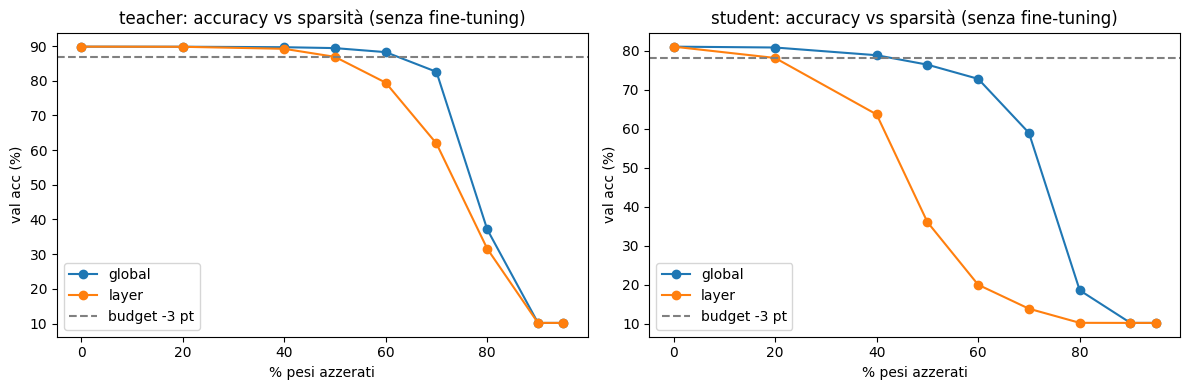

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (name, (_, base_acc, df)) in zip(ax, sweeps.items()):
    for mode, g in df.groupby("mode"):
        a.plot(g["sparsity"] * 100, g["val_acc"] * 100, marker="o", label=mode)
    a.axhline((base_acc - 0.03) * 100, color="gray", linestyle="--", label="budget -3 pt")
    a.set_title(f"{name}: accuracy vs sparsità (senza fine-tuning)")
    a.set_xlabel("% pesi azzerati"); a.set_ylabel("val acc (%)"); a.legend()
plt.tight_layout(); plt.show()

Considero la soluzione con maggior sparsità che mantiene massimo un drop 3% accuracy.  (salvata sempre in results/)

In [5]:
MAX_DROP = 3.0   # punti di accuracy persi sulla val al massimo rispetto al modello originale (senza pruning)

for name, (folded, base_acc, df) in sweeps.items():
    ok = df[df["drop"] <= MAX_DROP]
    best = ok.sort_values(["sparsity", "drop"], ascending=[False, True]).iloc[0]
    pruned = apply_masks(folded, compute_masks(folded, best["sparsity"], best["mode"]))

    _, test_acc = evaluate(pruned, test_loader, device)
    prof = profile_model(pruned, dtype="fp32", skip_zeros=True, latency=False,
                         size_mb=sparse_size_mb(pruned))
    save_result(f"{name}_unstruct", val_acc=best["val_acc"], test_acc=test_acc,
                sparsity=best["sparsity"], mode=best["mode"],
                nonzero_params=count_nonzero_params(pruned),
                macs_dense=count_macs(pruned), **prof)
    print(f"{name}: {best['mode']}, sparsità {best['sparsity'] * 100:.0f}% | test {test_acc * 100:.2f} | "
          f"{count_nonzero_params(pruned):,} non nulli | MACs sparsi {prof['macs'] / 1e6:.2f}M")

c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


teacher: global, sparsità 60% | test 87.58 | 6,213,603 non nulli | MACs sparsi 110.69M
student: global, sparsità 40% | test 78.52 | 147,018 non nulli | MACs sparsi 2.54M


Structured pruning

In [6]:
# TEST DI CORRETTEZZA:  (il numero di parametri deve scendere e i logit coincidere)
# - perchè in sostanza sto confrontando il modello small vero con quello "simulato" con maschere per testare la correttezza della funzione structured_keep

from src.prune import prune_structured, structured_keep, zero_out_structured, sweep_structured
from src.metrics import count_parameters

model = build_model("teacher")
model.load_state_dict(torch.load("../checkpoints/teacher_baseline.pt", map_location="cpu"))
folded = fold_bn(model)

small = prune_structured(folded, conv_ratio=0.3, fc_ratio=0.5)
masked = zero_out_structured(folded, *structured_keep(folded, 0.3, 0.5))

x, _ = next(iter(val_loader))
with torch.no_grad():
    print("max |diff| fisico vs azzerato:", (small(x) - masked(x)).abs().max().item())  # atteso ~1e-5
print("params:", count_parameters(folded)["total"], "->", count_parameters(small)["total"])
print("MACs (M):", count_macs(folded) / 1e6, "->", count_macs(small) / 1e6)

max |diff| fisico vs azzerato: 1.6689300537109375e-06
params: 15525258 -> 6507437
MACs (M): 215.689216 -> 104.900768


Sweep su griglia (skip prune sui primi 2 layer conv --> distrugge accuracy):

In [7]:
SKIP_FIRST = 2   # conv1 e conv2 non si potano
CONV_RATIOS = [0.0, 0.1]
FC_RATIOS = [0.0, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9]

struct = {}
for name in ["teacher", "student"]:
    model = build_model(name)
    model.load_state_dict(torch.load(f"../checkpoints/{name}_baseline.pt", map_location="cpu"))
    folded = fold_bn(model)
    base_acc, rows = sweep_structured(folded, val_loader, device, CONV_RATIOS, FC_RATIOS,
                                      skip_first=SKIP_FIRST)
    struct[name] = (folded, base_acc, pd.DataFrame(rows))
    print(f"\n{name}: calo di accuracy (punti) sulla val")
    display(struct[name][2].pivot(index="conv_ratio", columns="fc_ratio", values="drop")
            .round(2).style.background_gradient(cmap="RdYlGn_r"))

conv 0.00 | fc 0.00 | val 89.84 (Δ -0.00) | 15,525,258 params | 215.7M MACs
conv 0.00 | fc 0.30 | val 89.90 (Δ +0.06) | 13,194,821 params | 213.4M MACs
conv 0.00 | fc 0.50 | val 89.86 (Δ +0.02) | 11,848,586 params | 212.0M MACs
conv 0.00 | fc 0.60 | val 89.68 (Δ -0.16) | 11,238,921 params | 211.4M MACs
conv 0.00 | fc 0.70 | val 89.56 (Δ -0.28) | 10,670,451 params | 210.8M MACs
conv 0.00 | fc 0.80 | val 88.96 (Δ -0.88) | 10,146,885 params | 210.3M MACs
conv 0.00 | fc 0.90 | val 79.12 (Δ -10.72) | 9,662,567 params | 209.8M MACs
conv 0.10 | fc 0.00 | val 84.56 (Δ -5.28) | 13,398,335 params | 181.0M MACs
conv 0.10 | fc 0.30 | val 84.58 (Δ -5.26) | 11,193,154 params | 178.8M MACs
conv 0.10 | fc 0.50 | val 84.42 (Δ -5.42) | 9,930,559 params | 177.6M MACs
conv 0.10 | fc 0.60 | val 83.74 (Δ -6.10) | 9,362,714 params | 177.0M MACs
conv 0.10 | fc 0.70 | val 83.34 (Δ -6.50) | 8,836,064 params | 176.5M MACs
conv 0.10 | fc 0.80 | val 82.56 (Δ -7.28) | 8,354,114 params | 176.0M MACs
conv 0.10 | fc 0

fc_ratio,0.000000,0.300000,0.500000,0.600000,0.700000,0.800000,0.900000
conv_ratio,,,,,,,
0.000000,0.000000,-0.060000,-0.020000,0.160000,0.280000,0.880000,10.720000
0.100000,5.280000,5.260000,5.420000,6.100000,6.500000,7.280000,29.620000


c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


conv 0.00 | fc 0.00 | val 81.02 (Δ -0.00) | 244,538 params | 3.6M MACs
conv 0.00 | fc 0.30 | val 80.28 (Δ -0.74) | 207,673 params | 3.5M MACs
conv 0.00 | fc 0.50 | val 78.72 (Δ -2.30) | 186,362 params | 3.5M MACs
conv 0.00 | fc 0.60 | val 77.56 (Δ -3.46) | 176,547 params | 3.5M MACs
conv 0.00 | fc 0.70 | val 67.30 (Δ -13.72) | 167,703 params | 3.5M MACs
conv 0.00 | fc 0.80 | val 37.92 (Δ -43.10) | 159,289 params | 3.5M MACs
conv 0.00 | fc 0.90 | val 12.96 (Δ -68.06) | 151,733 params | 3.5M MACs
conv 0.10 | fc 0.00 | val 54.94 (Δ -26.08) | 213,227 params | 3.1M MACs
conv 0.10 | fc 0.30 | val 53.96 (Δ -27.06) | 178,210 params | 3.0M MACs
conv 0.10 | fc 0.50 | val 47.56 (Δ -33.46) | 158,123 params | 3.0M MACs
conv 0.10 | fc 0.60 | val 45.80 (Δ -35.22) | 148,932 params | 3.0M MACs
conv 0.10 | fc 0.70 | val 37.14 (Δ -43.88) | 140,688 params | 3.0M MACs
conv 0.10 | fc 0.80 | val 23.26 (Δ -57.76) | 132,898 params | 3.0M MACs
conv 0.10 | fc 0.90 | val 10.26 (Δ -70.76) | 125,942 params | 3.0M M

fc_ratio,0.000000,0.300000,0.500000,0.600000,0.700000,0.800000,0.900000
conv_ratio,,,,,,,
0.000000,0.000000,0.740000,2.300000,3.460000,13.720000,43.100000,68.060000
0.100000,26.080000,27.060000,33.460000,35.220000,43.880000,57.760000,70.760000


Come prima mantenuta la config con maggior pruning ma drop di accuracy massimo 3%

In [8]:
MAX_DROP = 3.0          # punti persi sulla val
OBJECTIVE = "params"    # oppure "macs"

for name, (folded, base_acc, df) in struct.items():
    ok = df[df["drop"] <= MAX_DROP]
    best = ok.sort_values([OBJECTIVE, "drop"]).iloc[0]
    conv_r = skip_first_ratios(folded, best["conv_ratio"], SKIP_FIRST)
    pruned = prune_structured(folded, conv_r, best["fc_ratio"])

    _, test_acc = evaluate(pruned, test_loader, device)
    prof = profile_model(pruned, dtype="fp32")
    save_result(f"{name}_struct", val_acc=best["val_acc"], test_acc=test_acc,
                conv_ratio=best["conv_ratio"], fc_ratio=best["fc_ratio"],
                skip_first=SKIP_FIRST, **prof)
    print(f"{name}: conv {best['conv_ratio']:.0%} (dal layer {SKIP_FIRST + 1}), fc {best['fc_ratio']:.0%} | "
          f"test {test_acc * 100:.2f} | {prof['params']:,} params | {prof['macs'] / 1e6:.1f}M MACs | "
          f"{prof['latency_ms_median']:.2f} ms")

teacher: conv 0% (dal layer 3), fc 80% | test 87.94 | 10,146,885 params | 210.3M MACs | 7.58 ms
student: conv 0% (dal layer 3), fc 50% | test 78.77 | 186,362 params | 3.5M MACs | 0.66 ms
